# NeoSentinel AI — Pipeline Pelatihan & Evaluasi Deteksi Tangisan Bayi (Raspberry Pi Edge)
Notebook ini dibagi per blok (cell) agar mudah dijalankan secara bertahap di dalam Virtual Environment (`.venv`):
1. **Cell 1**: Clone repositori dataset (`donateacry-corpus` & `ESC-50`) dan persiapan folder.
2. **Cell 2**: Pembuatan modul `features.py` (ekstraksi Log-Mel 98x40, RMS dBFS, serta fitur baseline).
3. **Cell 3**: Parsing metadata UUID perekam, pemotongan jendela 1 detik (hop 0.5 detik), dan *Silence Gating* (-50 dBFS).
4. **Cell 4**: Evaluasi Stage 1 dengan **5x3 Repeated Stratified Group K-Fold** + **95% Bootstrap CI** (Tabel 7).
5. **Cell 5**: Pelatihan model produksi final dan penyimpanan `stage1_cry.keras`, `stage1_cry_int8.tflite`, serta `stage1_norm.json`.
6. **Cell 6**: Pembuatan 4 Plot Publikasi (Confusion Matrix, Kurva PR, False Alarm/Jam, dan Analisis SHAP) beresolusi 300 DPI.
7. **Cell 7**: Evaluasi Stage 2 Eksploratori (5 Kelas Alasan Tangis & Varian Biner Hungry vs Other) untuk Tabel 8.
8. **Cell 8**: Pembuatan skrip `audio_detector.py` dan pengemasan `bundle_raspberry.zip` untuk dikirim ke Raspberry Pi.


In [1]:
# ==============================================================================
# CELL 1: PERSIAPAN FOLDER & CLONE DATASET DARI GITHUB
# ==============================================================================
import os
import subprocess

os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

if not os.path.exists("donateacry-corpus"):
    print("Mengunduh dataset Donate-a-Cry...")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gveres/donateacry-corpus.git"], check=True)
else:
    print("Folder 'donateacry-corpus' sudah tersedia.")

if not os.path.exists("ESC-50"):
    print("Mengunduh dataset ESC-50...")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/karolpiczak/ESC-50.git"], check=True)
else:
    print("Folder 'ESC-50' sudah tersedia.")

Mengunduh dataset Donate-a-Cry...


Cloning into 'donateacry-corpus'...


Mengunduh dataset ESC-50...


Cloning into 'ESC-50'...
Updating files: 100% (2011/2011), done.


### Cell 2: Buat Modul `features.py`
Modul ini ditulis menggunakan murni `numpy` dan `scipy` agar bisa langsung disalin ke Raspberry Pi tanpa perlu menginstal `librosa`.


In [2]:
# ==============================================================================
# CELL 2: BUAT FILE features.py DAN IMPORT KE NOTEBOOK
# ==============================================================================
features_code = '''import numpy as np
from scipy.fftpack import dct

SR = 8000
WIN_SAMPLES = 8000
HOP_SAMPLES = 4000
N_FFT = 256
WIN_LENGTH = 200
HOP_LENGTH = 80
N_MELS = 40
FMIN = 50.0
FMAX = 4000.0
FLOOR_DB = -80.0
SILENCE_DBFS = -50.0

def _hz_to_mel(hz):
    return 2595.0 * np.log10(1.0 + hz / 700.0)

def _mel_to_hz(mel):
    return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

def _create_mel_filterbank():
    mel_points = np.linspace(_hz_to_mel(FMIN), _hz_to_mel(FMAX), N_MELS + 2)
    hz_points = _mel_to_hz(mel_points)
    bin_points = np.floor((N_FFT + 1) * hz_points / SR).astype(int)
    fbank = np.zeros((N_MELS, N_FFT // 2 + 1), dtype=np.float32)
    for m in range(1, N_MELS + 1):
        f_m_minus, f_m, f_m_plus = bin_points[m - 1], bin_points[m], bin_points[m + 1]
        for k in range(f_m_minus, f_m):
            fbank[m - 1, k] = (k - f_m_minus) / max(1, (f_m - f_m_minus))
        for k in range(f_m, f_m_plus):
            fbank[m - 1, k] = (f_m_plus - k) / max(1, (f_m_plus - f_m))
    return fbank, hz_points[1:-1]

MEL_FBANK, MEL_CENTER_HZ = _create_mel_filterbank()
HANNING_WIN = np.hanning(WIN_LENGTH).astype(np.float32)

def rms_dbfs(w8k):
    w = np.atleast_2d(w8k).astype(np.float32)
    rms = np.sqrt(np.mean(w ** 2, axis=-1) + 1e-12)
    return 20.0 * np.log10(rms)

def _frame_signal(w):
    w = np.atleast_2d(w).astype(np.float32)
    num_frames = 1 + (w.shape[1] - WIN_LENGTH) // HOP_LENGTH
    shape = (w.shape[0], num_frames, WIN_LENGTH)
    strides = (w.strides[0], w.strides[1] * HOP_LENGTH, w.strides[1])
    return np.lib.stride_tricks.as_strided(w, shape=shape, strides=strides)

def logmel(w8k):
    frames = _frame_signal(w8k) * HANNING_WIN
    spec = np.fft.rfft(frames, n=N_FFT, axis=-1)
    power_spec = (np.abs(spec) ** 2) / N_FFT
    mel_energy = np.matmul(power_spec, MEL_FBANK.T)
    log_mel = 10.0 * np.log10(np.maximum(mel_energy, 1e-10))
    return np.maximum(log_mel, FLOOR_DB).astype(np.float32)

def extract_baselines(w8k):
    frames = _frame_signal(w8k) * HANNING_WIN
    ste = np.sum(frames ** 2, axis=-1)
    spec_mag = np.abs(np.fft.rfft(frames, n=N_FFT, axis=-1)) + 1e-10
    freqs = np.linspace(0, SR / 2.0, N_FFT // 2 + 1, dtype=np.float32)

    centroid = np.sum(spec_mag * freqs, axis=-1) / np.sum(spec_mag, axis=-1)
    bw = np.sqrt(np.sum(((freqs - centroid[..., None]) ** 2) * spec_mag, axis=-1) / np.sum(spec_mag, axis=-1))

    fahmi_feat = np.stack([
        np.min(ste, axis=-1), np.max(ste, axis=-1), np.mean(ste, axis=-1), np.std(ste, axis=-1),
        np.mean(centroid, axis=-1), np.std(centroid, axis=-1),
        np.mean(bw, axis=-1), np.std(bw, axis=-1)
    ], axis=-1).astype(np.float32)

    lm = logmel(w8k)
    mfcc = dct(lm, type=2, axis=-1, norm='ortho')[..., :13]
    mfcc_feat = np.concatenate([np.mean(mfcc, axis=1), np.std(mfcc, axis=1)], axis=-1).astype(np.float32)
    return fahmi_feat, mfcc_feat
'''

with open("features.py", "w", encoding="utf-8") as f:
    f.write(features_code)

import features
from features import SR, WIN_SAMPLES, HOP_SAMPLES, SILENCE_DBFS, logmel, rms_dbfs, extract_baselines
print("Modul features.py siap! Dimensi output logmel per jendela 1 detik:",
      logmel(features.np.zeros((1, 8000), dtype=features.np.float32)).shape)

Modul features.py siap! Dimensi output logmel per jendela 1 detik: (1, 98, 40)


### Cell 3: Muat Dataset, Parsing Grup UUID, dan Silence Gating
Memisahkan grup berdasarkan UUID aplikasi perekam pada *Donate-a-Cry* dan `src_file` pada *ESC-50*, serta membuang jendela jeda napas yang hening (`< -50 dBFS`) di dalam klip tangisan.


In [3]:
# ==============================================================================
# CELL 3: MUAT AUDIO, PARSING METADATA GRUP, DAN EKSTRAKSI FITUR
# ==============================================================================
import re
import glob
from math import gcd
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly

REASON_MAP = {"hungry": 0, "belly_pain": 1, "burping": 2, "discomfort": 3, "tired": 4}
ESC_NON_CRY_CLASSES = [
    "clapping", "coughing", "sneezing", "laughing", "footsteps",
    "door_wood_knock", "door_wood_creaks", "washing_machine",
    "vacuum_cleaner", "clock_alarm", "clock_tick", "glass_breaking",
    "breathing", "snoring", "drinking_sipping", "keyboard_typing", "mouse_click",
    "cat", "sheep", "hen", "siren", "church_bells"
]

def load_audio_8k(wav_path):
    y, sr_orig = sf.read(wav_path, dtype="float32", always_2d=True)
    y = np.mean(y, axis=1)
    if sr_orig != SR:
        g = gcd(SR, sr_orig)
        y = resample_poly(y, SR // g, sr_orig // g).astype(np.float32)
    return y

def slice_windows(y):
    if len(y) < WIN_SAMPLES:
        y = np.pad(y, (0, WIN_SAMPLES - len(y)), mode="constant")
    starts = range(0, len(y) - WIN_SAMPLES + 1, HOP_SAMPLES)
    return np.stack([y[s:s + WIN_SAMPLES] for s in starts], axis=0)

clips_data = []
uuid_regex = re.compile(r"^([0-9A-Fa-f-]{36})-")
removed_silent_windows = 0

dac_root = "donateacry-corpus/donateacry_corpus_cleaned_and_updated_data"
for folder_name, reason_idx in REASON_MAP.items():
    for wav_path in sorted(glob.glob(os.path.join(dac_root, folder_name, "*.wav"))):
        fname = os.path.basename(wav_path)
        m = uuid_regex.match(fname)
        group_id = "dac_" + (m.group(1) if m else fname[:15])

        y = load_audio_8k(wav_path)
        wins = slice_windows(y)
        dbfs = rms_dbfs(wins)

        active_mask = dbfs >= SILENCE_DBFS
        removed_silent_windows += int(np.sum(~active_mask))
        if np.sum(active_mask) == 0:
            active_mask[np.argmax(dbfs)] = True
        wins_clean = wins[active_mask]

        mels = logmel(wins_clean)
        fahmis, mfccs = extract_baselines(wins_clean)

        clips_data.append({
            "clip_id": fname, "group_id": group_id,
            "stage1_label": 1, "stage2_label": reason_idx,
            "source": "donate_a_cry", "duration_sec": len(y) / SR,
            "mels": mels, "fahmis": fahmis, "mfccs": mfccs,
            "dbfs": dbfs[active_mask]
        })

esc_meta = pd.read_csv("ESC-50/meta/esc50.csv")
for _, row in esc_meta.iterrows():
    cat = row["category"]
    if cat == "crying_baby":
        s1_label = 1
    elif cat in ESC_NON_CRY_CLASSES:
        s1_label = 0
    else:
        continue

    wav_path = os.path.join("ESC-50/audio", row["filename"])
    y = load_audio_8k(wav_path)
    wins = slice_windows(y)
    dbfs = rms_dbfs(wins)

    if s1_label == 1:
        active_mask = dbfs >= SILENCE_DBFS
        if np.sum(active_mask) == 0:
            active_mask[np.argmax(dbfs)] = True
        wins = wins[active_mask]
        dbfs = dbfs[active_mask]

    mels = logmel(wins)
    fahmis, mfccs = extract_baselines(wins)

    clips_data.append({
        "clip_id": row["filename"],
        "group_id": "esc_" + str(row["src_file"]),
        "stage1_label": s1_label, "stage2_label": -1,
        "source": "esc50", "duration_sec": len(y) / SR,
        "mels": mels, "fahmis": fahmis, "mfccs": mfccs,
        "dbfs": dbfs
    })

print("Total klip dimuat              :", len(clips_data))
print(" - Klip Tangisan (Cry = 1)     :", sum(1 for c in clips_data if c["stage1_label"] == 1))
print(" - Klip Non-Tangis (Non-Cry=0) :", sum(1 for c in clips_data if c["stage1_label"] == 0))
print("Jendela hening dalam klip tangis yang dibuang:", removed_silent_windows)

Total klip dimuat              : 1377
 - Klip Tangisan (Cry = 1)     : 497
 - Klip Non-Tangis (Non-Cry=0) : 880
Jendela hening dalam klip tangis yang dibuang: 468


### Cell 4: Evaluasi Stage 1 (5x3 Repeated Stratified Group K-Fold + Bootstrap 95% CI)
Melatih dan mengevaluasi 4 metode pada pembagian grup yang sama untuk mengisi **Tabel 7**.


In [4]:
# ==============================================================================
# CELL 4: EVALUASI 5x3 REPEATED GROUP CV + BOOTSTRAP 95% CI (UNTUK TABEL 7)
# ==============================================================================
import tensorflow as tf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

tf.get_logger().setLevel("ERROR")

def build_cnn(num_classes=2):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(98, 40)),
        tf.keras.layers.Conv1D(8, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling1D(pool_size=2),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Conv1D(16, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling1D(pool_size=2),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def augment_mel_batch(X, y):
    X_aug = X.copy()
    rng = np.random.default_rng(42)
    X_aug += rng.normal(0, 0.15, size=X_aug.shape).astype(np.float32)
    for i in range(len(X_aug)):
        f0 = rng.integers(0, 36)
        X_aug[i, :, f0:f0 + 3] = 0.0
    return np.concatenate([X, X_aug], axis=0), np.concatenate([y, y], axis=0)

def convert_and_eval_int8(model, X_train_norm, X_test_norm):
    def rep_data_gen():
        idx = np.random.choice(len(X_train_norm), size=min(200, len(X_train_norm)), replace=False)
        for i in idx:
            yield [X_train_norm[i:i + 1].astype(np.float32)]

    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = rep_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_bytes = converter.convert()

    it = tf.lite.Interpreter(model_content=tflite_bytes)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    s_in, z_in = inp["quantization"]
    s_out, z_out = out["quantization"]

    probs = []
    for x in X_test_norm:
        xq = np.clip(np.round(x / s_in + z_in), -128, 127).astype(np.int8)
        it.set_tensor(inp["index"], xq[None, ...])
        it.invoke()
        oq = it.get_tensor(out["index"])[0]
        probs.append((oq.astype(np.float32) - z_out) * s_out)
    return np.array(probs), len(tflite_bytes) / 1024.0, tflite_bytes

def bootstrap_group_ci(y_true, y_pred, groups, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    boot_f1s = []
    for _ in range(n_boot):
        sampled_g = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in sampled_g])
        boot_f1s.append(f1_score(y_true[idx], y_pred[idx], average="macro"))
    return np.percentile(boot_f1s, [2.5, 97.5])

y_clips = np.array([c["stage1_label"] for c in clips_data])
g_clips = np.array([c["group_id"] for c in clips_data])

results_15_runs = {"knn": [], "rf_mfcc": [], "cnn_f32": [], "cnn_int8": []}
oof_true, oof_groups = [], []
oof_scores = {"knn": [], "rf_mfcc": [], "cnn_f32": [], "cnn_int8": []}
window_probs_non_cry = []
non_cry_hours_per_repeat = 0.0

for seed in (42, 43, 44):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

    for fold, (tr_idx, te_idx) in enumerate(sgkf.split(clips_data, y_clips, g_clips), 1):
        X_mel_tr = np.vstack([clips_data[i]["mels"] for i in tr_idx])
        X_fah_tr = np.vstack([clips_data[i]["fahmis"] for i in tr_idx])
        X_mfc_tr = np.vstack([clips_data[i]["mfccs"] for i in tr_idx])
        y_win_tr = np.concatenate([[clips_data[i]["stage1_label"]] * len(clips_data[i]["mels"]) for i in tr_idx])

        mel_mean = X_mel_tr.mean(axis=(0, 1), keepdims=True)
        mel_std = X_mel_tr.std(axis=(0, 1), keepdims=True) + 1e-6
        X_mel_tr_norm = (X_mel_tr - mel_mean) / mel_std

        scaler_fah = StandardScaler().fit(X_fah_tr)
        scaler_mfc = StandardScaler().fit(X_mfc_tr)

        knn = KNeighborsClassifier(n_neighbors=5).fit(scaler_fah.transform(X_fah_tr), y_win_tr)
        rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=seed, n_jobs=-1)
        rf.fit(scaler_mfc.transform(X_mfc_tr), y_win_tr)

        X_aug, y_aug = augment_mel_batch(X_mel_tr_norm, y_win_tr)
        n0, n1 = np.sum(y_aug == 0), np.sum(y_aug == 1)
        cw = {0: len(y_aug) / (2.0 * n0), 1: len(y_aug) / (2.0 * n1)}
        cnn = build_cnn(num_classes=2)
        cnn.fit(X_aug, y_aug, epochs=20, batch_size=64, class_weight=cw, verbose=0)

        X_mel_te_all = (np.vstack([clips_data[i]["mels"] for i in te_idx]) - mel_mean) / mel_std
        probs_i8_all, kb_size, _ = convert_and_eval_int8(cnn, X_mel_tr_norm, X_mel_te_all)

        y_t, p_knn, p_rf, p_f32, p_i8 = [], [], [], [], []
        ptr = 0
        for i in te_idx:
            c = clips_data[i]
            nw = len(c["mels"])
            y_t.append(c["stage1_label"])

            s_knn = knn.predict_proba(scaler_fah.transform(c["fahmis"]))[:, 1].mean()
            s_rf = rf.predict_proba(scaler_mfc.transform(c["mfccs"]))[:, 1].mean()
            c_mel_norm = (c["mels"] - mel_mean) / mel_std
            w_f32 = cnn.predict(c_mel_norm, verbose=0)[:, 1]
            w_i8 = probs_i8_all[ptr:ptr + nw, 1]
            ptr += nw

            w_f32 = np.where(c["dbfs"] < SILENCE_DBFS, 0.0, w_f32)
            w_i8 = np.where(c["dbfs"] < SILENCE_DBFS, 0.0, w_i8)

            p_knn.append(s_knn)
            p_rf.append(s_rf)
            p_f32.append(w_f32.mean())
            p_i8.append(w_i8.mean())

            if seed == 42:
                oof_true.append(c["stage1_label"])
                oof_groups.append(c["group_id"])
                oof_scores["knn"].append(s_knn)
                oof_scores["rf_mfcc"].append(s_rf)
                oof_scores["cnn_f32"].append(w_f32.mean())
                oof_scores["cnn_int8"].append(w_i8.mean())
                if c["stage1_label"] == 0:
                    non_cry_hours_per_repeat += c["duration_sec"] / 3600.0
                    window_probs_non_cry.append(w_i8)

        for k, sc in zip(["knn", "rf_mfcc", "cnn_f32", "cnn_int8"], [p_knn, p_rf, p_f32, p_i8]):
            preds = (np.array(sc) >= 0.5).astype(int)
            results_15_runs[k].append((accuracy_score(y_t, preds), f1_score(y_t, preds, average="macro")))

    mean_f1_seed = np.mean([x[1] for x in results_15_runs["cnn_int8"][-5:]])
    print("Selesai Repeat Seed", seed, "| Mean Macro-F1 CNN int8:", round(mean_f1_seed, 4))

oof_true = np.array(oof_true)
oof_groups = np.array(oof_groups)

print("\n" + "=" * 75)
print("HASIL FINAL STAGE 1 (5x3 REPEATED GROUPED CV + 95% BOOTSTRAP CI) -> TABEL 7")
print("=" * 75)
for name, label in [
    ("knn", "Energy+Spectrum k-NN [6]"),
    ("rf_mfcc", "MFCC + Random Forest"),
    ("cnn_f32", "1D CNN float32 (Raspberry/PC)"),
    ("cnn_int8", "1D CNN int8 (Deploy TFLite)")
]:
    accs = [v[0] * 100 for v in results_15_runs[name]]
    f1s = [v[1] for v in results_15_runs[name]]
    oof_pred = (np.array(oof_scores[name]) >= 0.5).astype(int)
    ci_low, ci_high = bootstrap_group_ci(oof_true, oof_pred, oof_groups)
    print(f"{label:30s} | Acc: {np.mean(accs):.2f}% +/- {np.std(accs):.2f}% | "
          f"Macro-F1: {np.mean(f1s):.4f} (95% CI: [{ci_low:.4f}, {ci_high:.4f}])")
print(f"Ukuran File Model 1D CNN (int8): {kb_size:.2f} KB")

I0000 00:00:1793983594.849920   42959 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793983594.854782   42959 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793983595.015744   42959 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793983596.425416   42959 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Saved artifact at '/tmp/tmpfrv5n2oz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140096892670256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096895285872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096895283952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096895284192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096895285152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096895283472: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793983632.399195   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793983632.399223   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793983632.399975   42959 reader.cc:83] Reading SavedModel from: /tmp/tmpfrv5n2oz
I0000 00:00:1793983632.400673   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793983632.400694   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpfrv5n2oz
I0000 00:00:1793983632.405155   42959 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793983632.405910   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793983632.442394   42959 loader.cc:221] Run

Saved artifact at '/tmp/tmpuikchi1v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_9')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140095293932560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293938800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293941200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293941680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293946240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293937600: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793983701.501773   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793983701.501792   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793983701.501976   42959 reader.cc:83] Reading SavedModel from: /tmp/tmpuikchi1v
I0000 00:00:1793983701.502479   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793983701.502489   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpuikchi1v
I0000 00:00:1793983701.506242   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793983701.529272   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpuikchi1v
I0000 00:00:1793983701.537683   42959 loader.c

Saved artifact at '/tmp/tmpcjcw822k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_18')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140096553616400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096553620000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096553620240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096553628160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096553615680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096553625520: TensorSpec(shape=(), dtype=tf.resource, name=None)


... (22 outputs left out)

/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984469.836769   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984469.836800   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984469.836998   42959 reader.cc:83] Reading SavedModel from: /tmp/tmpdvu1elaf
I0000 00:00:1793984469.837691   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984469.837703   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpdvu1elaf
I0000 00:00:1793984469.841772   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984469.865793   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpdvu1elaf
I0000 00:00:1793984469.874858   42959 loader.c

Saved artifact at '/tmp/tmpmshhzc2v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_126')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140096484515168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096484520688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096484516608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096484513008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096484507968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096484516128: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984531.149543   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984531.149569   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984531.149752   42959 reader.cc:83] Reading SavedModel from: /tmp/tmpmshhzc2v
I0000 00:00:1793984531.150324   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984531.150334   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpmshhzc2v
I0000 00:00:1793984531.154076   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984531.177480   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpmshhzc2v
I0000 00:00:1793984531.186064   42959 loader.c

Selesai Repeat Seed 44 | Mean Macro-F1 CNN int8: 0.9161

HASIL FINAL STAGE 1 (5x3 REPEATED GROUPED CV + 95% BOOTSTRAP CI) -> TABEL 7
Energy+Spectrum k-NN [6]       | Acc: 83.88% +/- 2.55% | Macro-F1: 0.8314 (95% CI: [0.8135, 0.8612])
MFCC + Random Forest           | Acc: 92.69% +/- 1.90% | Macro-F1: 0.9224 (95% CI: [0.9093, 0.9433])
1D CNN float32 (Raspberry/PC)  | Acc: 91.86% +/- 2.53% | Macro-F1: 0.9125 (95% CI: [0.8914, 0.9339])
1D CNN int8 (Deploy TFLite)    | Acc: 91.89% +/- 2.47% | Macro-F1: 0.9127 (95% CI: [0.8916, 0.9337])
Ukuran File Model 1D CNN (int8): 8.30 KB


### Cell 5: Latih Model Produksi Final & Ekspor ke Folder `models/`
Menyimpan `stage1_cry.keras`, `stage1_cry_int8.tflite`, dan parameter normalisasi `stage1_norm.json` agar di Raspberry Pi tidak perlu melakukan training ulang.


In [5]:
# ==============================================================================
# CELL 5: SIMPAN MODEL PRODUKSI FINAL (.keras, .tflite, stage1_norm.json)
# ==============================================================================
import json
import time

X_all_mel = np.vstack([c["mels"] for c in clips_data])
y_all_win = np.concatenate([[c["stage1_label"]] * len(c["mels"]) for c in clips_data])

final_mean = X_all_mel.mean(axis=(0, 1), keepdims=True)
final_std = X_all_mel.std(axis=(0, 1), keepdims=True) + 1e-6
X_all_norm = (X_all_mel - final_mean) / final_std

X_all_aug, y_all_aug = augment_mel_batch(X_all_norm, y_all_win)
n0, n1 = np.sum(y_all_aug == 0), np.sum(y_all_aug == 1)
cw_final = {0: len(y_all_aug) / (2.0 * n0), 1: len(y_all_aug) / (2.0 * n1)}

tf.random.set_seed(42)
final_cnn = build_cnn(num_classes=2)
final_cnn.fit(X_all_aug, y_all_aug, epochs=25, batch_size=64, class_weight=cw_final, verbose=0)

final_cnn.save("models/stage1_cry.keras")
_, final_kb, final_tflite_bytes = convert_and_eval_int8(final_cnn, X_all_norm, X_all_norm[:10])
with open("models/stage1_cry_int8.tflite", "wb") as f:
    f.write(final_tflite_bytes)

it_bench = tf.lite.Interpreter(model_path="models/stage1_cry_int8.tflite")
it_bench.allocate_tensors()
inp_b = it_bench.get_input_details()[0]
dummy_in = np.zeros((1, 98, 40), dtype=np.int8)
for _ in range(20):
    it_bench.set_tensor(inp_b["index"], dummy_in)
    it_bench.invoke()
t0 = time.perf_counter()
for _ in range(500):
    it_bench.set_tensor(inp_b["index"], dummy_in)
    it_bench.invoke()
infer_ms = ((time.perf_counter() - t0) / 500.0) * 1000.0

norm_meta = {
    "sr": int(features.SR),
    "win_samples": int(features.WIN_SAMPLES),
    "hop_samples": int(features.HOP_SAMPLES),
    "n_mels": int(features.N_MELS),
    "floor_db": float(features.FLOOR_DB),
    "silence_dbfs": float(features.SILENCE_DBFS),
    "threshold": 0.85,
    "consecutive_windows": 3,
    "mean": final_mean[0].tolist(),
    "std": final_std[0].tolist()
}
with open("models/stage1_norm.json", "w", encoding="utf-8") as f:
    json.dump(norm_meta, f, indent=2)

print("Berhasil menyimpan:")
print(" - models/stage1_cry.keras")
print(f" - models/stage1_cry_int8.tflite ({final_kb:.2f} KB)")
print(" - models/stage1_norm.json")
print(f"Waktu inferensi rata-rata TFLite int8: {infer_ms:.3f} ms per jendela 1 detik")

Saved artifact at '/tmp/tmpcwhmmjv7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_135')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140095293945760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293934960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293947440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293934720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293946000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293940480: TensorSpec(shape=(), dtype=tf.resource, name=None)
Berhasil menyimpan:
 - models/stage1_cry.keras
 - models/stage1_cry_int8.tflite (8.30 KB)
 - models/stage1_norm.json
Waktu inferensi rata-rata TFLite int8: 0.005 ms per jendela 1 detik


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984664.763084   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984664.763112   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984664.763304   42959 reader.cc:83] Reading SavedModel from: /tmp/tmpcwhmmjv7
I0000 00:00:1793984664.763820   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984664.763828   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpcwhmmjv7
I0000 00:00:1793984664.767549   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984664.790619   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpcwhmmjv7
I0000 00:00:1793984664.798910   42959 loader.c

### Cell 6: Buat 4 Plot Publikasi (300 DPI) & Analisis SHAP
Menghasilkan Confusion Matrix, Kurva Precision-Recall, Kurva False Events per Jam vs Threshold, dan tingkat kepentingan 40 pita frekuensi Mel (SHAP / Occlusion Attribution).


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/keras/src/models/functional.py:293: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_135
Received: inputs=['Tensor(shape=(60, 98, 40))']
  warnings.warn(msg)
/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/keras/src/models/functional.py:293: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_135
Received: inputs=['Tensor(shape=(50, 98, 40))']
  warnings.warn(msg)


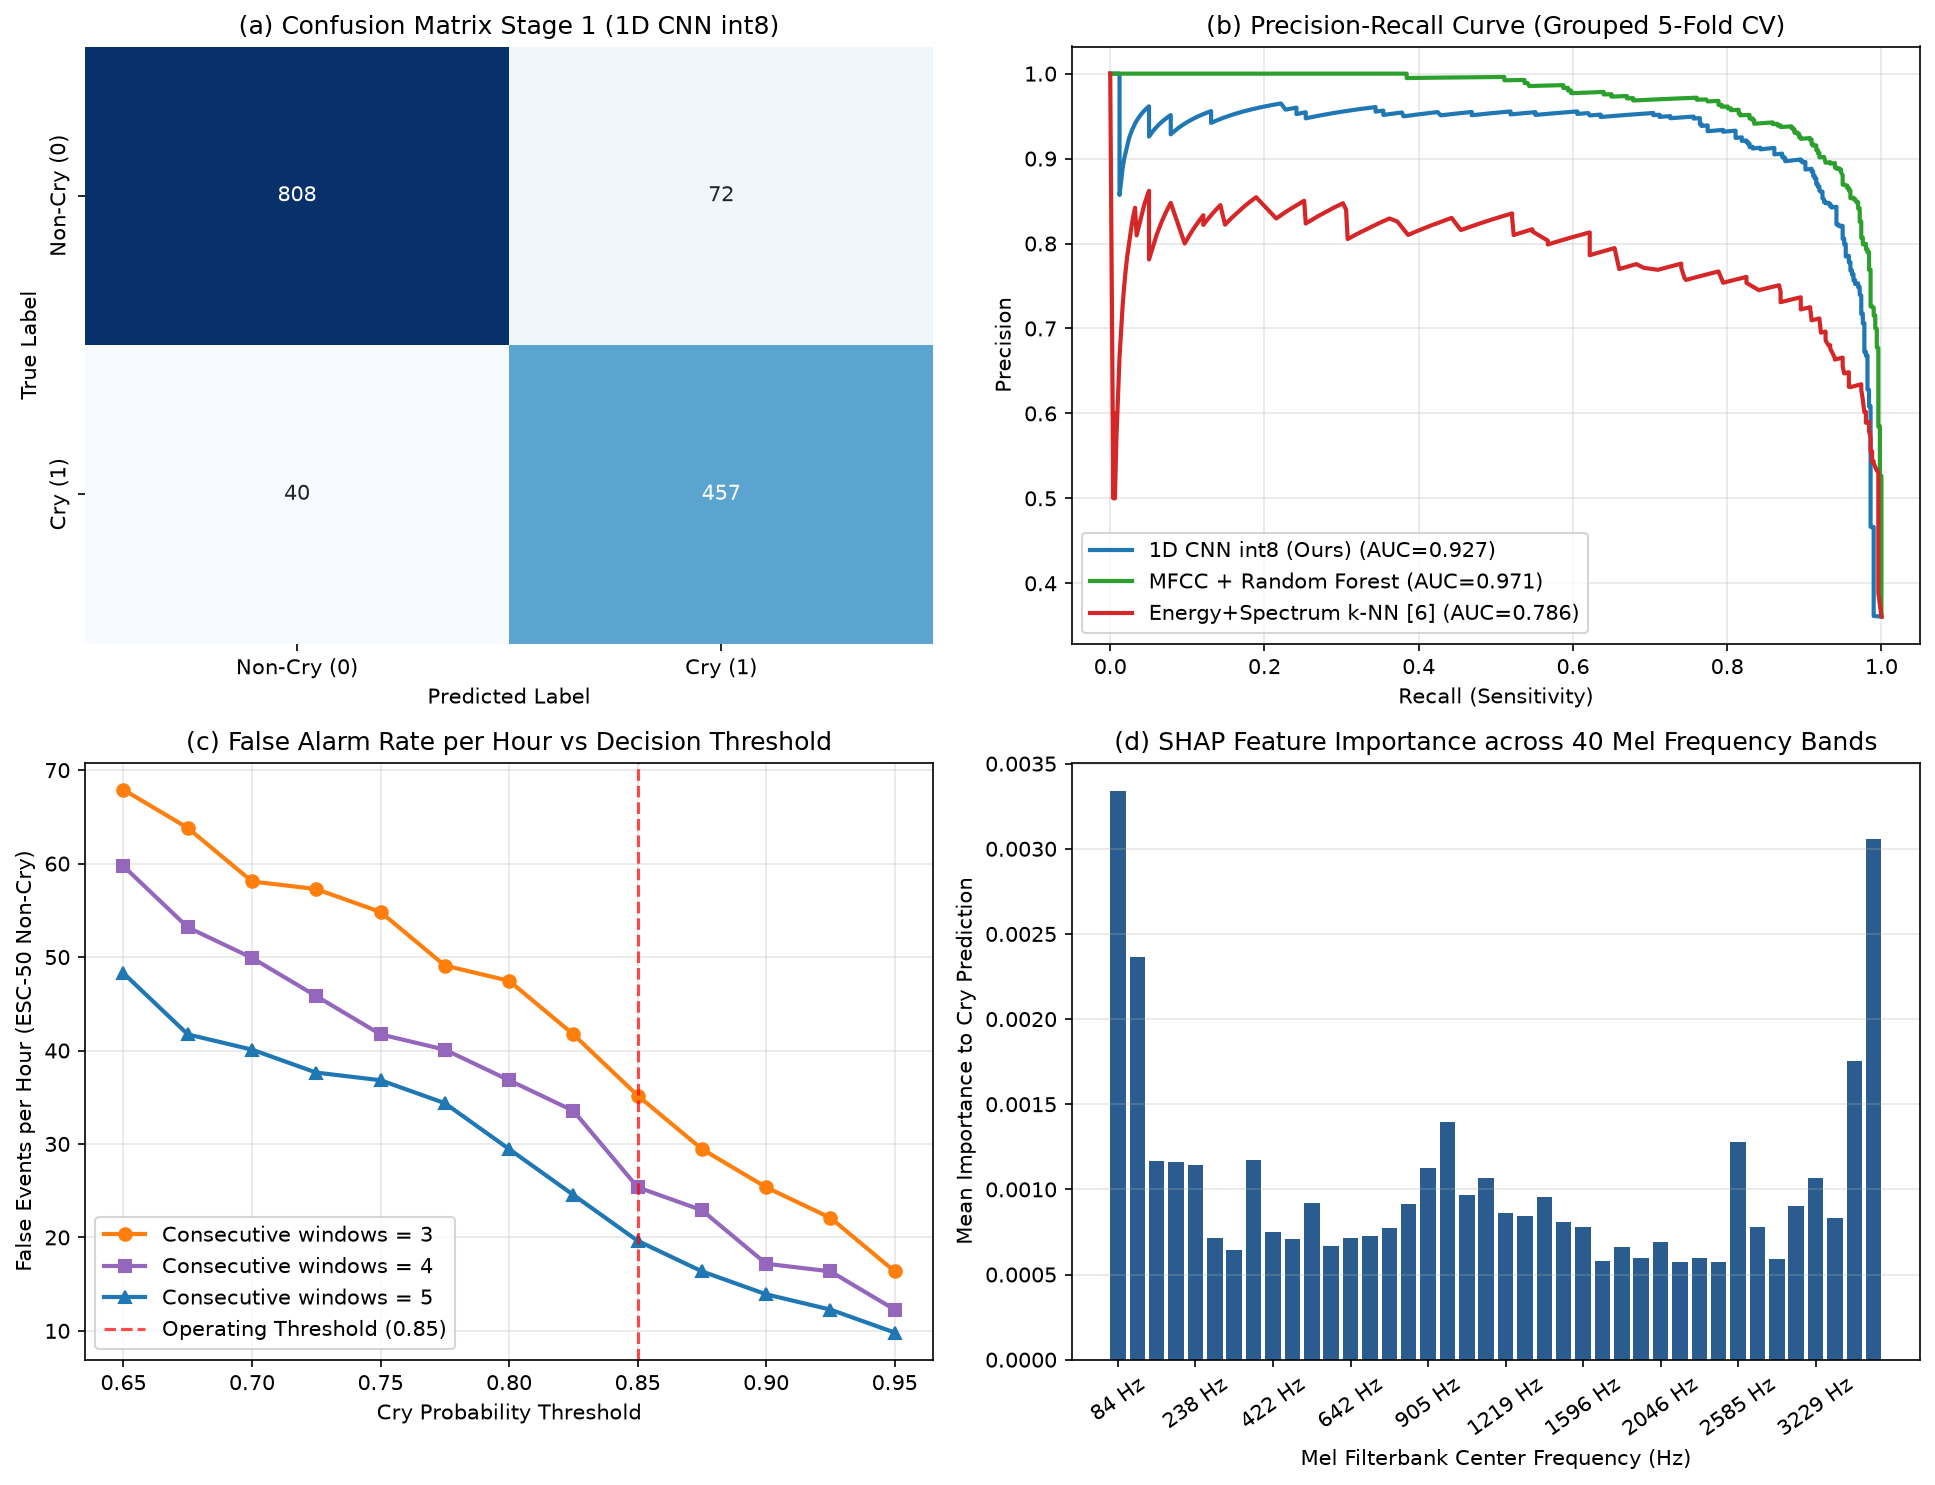

Gambar disimpan di: plots/fig_stage1_evaluation_and_shap.png


In [6]:
# ==============================================================================
# CELL 6: GENERATE 4 PLOT PUBLIKASI + SHAP FEATURE ATTRIBUTION
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import precision_recall_curve, auc, confusion_matrix

plt.rcParams.update({"font.size": 10, "figure.dpi": 150})
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

cm = confusion_matrix(oof_true, (np.array(oof_scores["cnn_int8"]) >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, 0],
            xticklabels=["Non-Cry (0)", "Cry (1)"], yticklabels=["Non-Cry (0)", "Cry (1)"])
axes[0, 0].set_title("(a) Confusion Matrix Stage 1 (1D CNN int8)")
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Label")

for key, label, col in [
    ("cnn_int8", "1D CNN int8 (Ours)", "#1f77b4"),
    ("rf_mfcc", "MFCC + Random Forest", "#2ca02c"),
    ("knn", "Energy+Spectrum k-NN [6]", "#d62728")
]:
    prec, rec, _ = precision_recall_curve(oof_true, oof_scores[key])
    pr_auc = auc(rec, prec)
    axes[0, 1].plot(rec, prec, lw=2, color=col, label=f"{label} (AUC={pr_auc:.3f})")
axes[0, 1].set_title("(b) Precision-Recall Curve (Grouped 5-Fold CV)")
axes[0, 1].set_xlabel("Recall (Sensitivity)")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(loc="lower left")
axes[0, 1].grid(True, alpha=0.3)

thresholds = np.linspace(0.65, 0.95, 13)
for win_req, col, marker in [(3, "#ff7f0e", "o"), (4, "#9467bd", "s"), (5, "#1f77b4", "^")]:
    fa_rates = []
    for th in thresholds:
        fe = 0
        for w_probs in window_probs_non_cry:
            if len(w_probs) >= win_req:
                m_avg = np.convolve(w_probs, np.ones(win_req) / win_req, mode="valid")
                if np.any(m_avg >= th):
                    fe += 1
        fa_rates.append(fe / non_cry_hours_per_repeat)
    axes[1, 0].plot(thresholds, fa_rates, marker=marker, lw=2, color=col,
                    label=f"Consecutive windows = {win_req}")
axes[1, 0].axvline(0.85, color="red", linestyle="--", alpha=0.7, label="Operating Threshold (0.85)")
axes[1, 0].set_title("(c) False Alarm Rate per Hour vs Decision Threshold")
axes[1, 0].set_xlabel("Cry Probability Threshold")
axes[1, 0].set_ylabel("False Events per Hour (ESC-50 Non-Cry)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

bg_idx = np.random.choice(len(X_all_norm), size=80, replace=False)
cry_win_idx = np.where(y_all_win == 1)[0][:60]
background_data = X_all_norm[bg_idx]
test_cry_windows = X_all_norm[cry_win_idx]

try:
    explainer = shap.GradientExplainer(final_cnn, background_data)
    shap_vals = explainer.shap_values(test_cry_windows)
    if isinstance(shap_vals, list):
        sv_cry = np.abs(shap_vals[1])
    elif shap_vals.ndim == 4:
        sv_cry = np.abs(shap_vals[..., 1])
    else:
        sv_cry = np.abs(shap_vals)
    freq_importance = sv_cry.mean(axis=(0, 1))
    method_title = "(d) SHAP Feature Importance across 40 Mel Frequency Bands"
except Exception:
    base_p = final_cnn.predict(test_cry_windows, verbose=0)[:, 1].mean()
    freq_importance = np.zeros(40)
    for b in range(40):
        X_occ = test_cry_windows.copy()
        X_occ[:, :, b] = 0.0
        freq_importance[b] = max(0.0, base_p - final_cnn.predict(X_occ, verbose=0)[:, 1].mean())
    method_title = "(d) Frequency Band Attribution across 40 Mel Bands"

hz_labels = [f"{int(hz)} Hz" for hz in features.MEL_CENTER_HZ]
axes[1, 1].bar(range(40), freq_importance, color="#2b5c8f")
tick_pos = np.arange(0, 40, 4)
axes[1, 1].set_xticks(tick_pos)
axes[1, 1].set_xticklabels([hz_labels[i] for i in tick_pos], rotation=35)
axes[1, 1].set_title(method_title)
axes[1, 1].set_xlabel("Mel Filterbank Center Frequency (Hz)")
axes[1, 1].set_ylabel("Mean Importance to Cry Prediction")
axes[1, 1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("plots/fig_stage1_evaluation_and_shap.png", dpi=300)
plt.show()
print("Gambar disimpan di: plots/fig_stage1_evaluation_and_shap.png")

### Cell 7: Evaluasi Stage 2 Eksploratori (5 Kelas Alasan Tangis & Varian Biner)
Menghitung metrik untuk **Tabel 8** pada klip *Donate-a-Cry*.


In [7]:
# ==============================================================================
# CELL 7: EVALUASI STAGE 2 EKSPLORATORI (5 KELAS & VARIAN BINER) -> TABEL 8
# ==============================================================================
from sklearn.metrics import balanced_accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

dac_clips = [c for c in clips_data if c["source"] == "donate_a_cry"]
y_s2 = np.array([c["stage2_label"] for c in dac_clips])
g_s2 = np.array([c["group_id"] for c in dac_clips])

sgkf_s2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
true_5c, pred_5c_i8, pred_bin_i8 = [], [], []

for tr_idx, te_idx in sgkf_s2.split(dac_clips, y_s2, g_s2):
    X_tr = np.vstack([dac_clips[i]["mels"] for i in tr_idx])
    y_tr_5c = np.concatenate([[dac_clips[i]["stage2_label"]] * len(dac_clips[i]["mels"]) for i in tr_idx])
    y_tr_bin = (y_tr_5c == 0).astype(int)

    m_mean = X_tr.mean(axis=(0, 1), keepdims=True)
    m_std = X_tr.std(axis=(0, 1), keepdims=True) + 1e-6
    X_tr_norm = (X_tr - m_mean) / m_std

    classes_u = np.unique(y_tr_5c)
    cw_5c = dict(zip(classes_u, compute_class_weight("balanced", classes=classes_u, y=y_tr_5c)))
    cnn_5c = build_cnn(num_classes=5)
    cnn_5c.fit(X_tr_norm, y_tr_5c, epochs=25, batch_size=32, class_weight=cw_5c, verbose=0)

    cw_bin = dict(zip([0, 1], compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr_bin)))
    cnn_bin = build_cnn(num_classes=2)
    cnn_bin.fit(X_tr_norm, y_tr_bin, epochs=25, batch_size=32, class_weight=cw_bin, verbose=0)

    X_te_all = (np.vstack([dac_clips[i]["mels"] for i in te_idx]) - m_mean) / m_std
    p5_all, _, _ = convert_and_eval_int8(cnn_5c, X_tr_norm, X_te_all)
    pb_all, _, _ = convert_and_eval_int8(cnn_bin, X_tr_norm, X_te_all)

    ptr = 0
    for i in te_idx:
        nw = len(dac_clips[i]["mels"])
        true_5c.append(dac_clips[i]["stage2_label"])
        pred_5c_i8.append(np.argmax(p5_all[ptr:ptr + nw].mean(axis=0)))
        pred_bin_i8.append(int(pb_all[ptr:ptr + nw, 1].mean() >= 0.5))
        ptr += nw

true_5c = np.array(true_5c)
pred_5c_i8 = np.array(pred_5c_i8)
true_bin = (true_5c == 0).astype(int)
pred_bin_i8 = np.array(pred_bin_i8)
maj_pred = np.zeros_like(true_5c)

print("=== RINGKASAN STAGE 2 (EKSPLORATORI) ===")
print(f"1. Majority Baseline (Selalu Hungry) -> Acc: {accuracy_score(true_5c, maj_pred)*100:.2f}% | "
      f"Bal-Acc: {balanced_accuracy_score(true_5c, maj_pred)*100:.2f}% | Macro-F1: {f1_score(true_5c, maj_pred, average='macro'):.4f}")
print(f"2. 1D CNN int8 (5 Kelas + CW)        -> Acc: {accuracy_score(true_5c, pred_5c_i8)*100:.2f}% | "
      f"Bal-Acc: {balanced_accuracy_score(true_5c, pred_5c_i8)*100:.2f}% | Macro-F1: {f1_score(true_5c, pred_5c_i8, average='macro'):.4f}")
print(f"3. 1D CNN int8 Biner (Hungry vs Non) -> Acc: {accuracy_score(true_bin, pred_bin_i8)*100:.2f}% | "
      f"Bal-Acc: {balanced_accuracy_score(true_bin, pred_bin_i8)*100:.2f}% | Macro-F1: {f1_score(true_bin, pred_bin_i8, average='macro'):.4f}\n")

print("=== TABEL 8: RINCIAN PER KELAS STAGE 2 (5 KELAS, INT8) ===")
names_5c = ["Hungry (382)", "Belly pain (16)", "Burping (8)", "Discomfort (27)", "Tired (24)"]
print(classification_report(true_5c, pred_5c_i8, target_names=names_5c, digits=4, zero_division=0))

Saved artifact at '/tmp/tmppwkbsvsr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_144')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140096824649888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824648688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824651088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824649168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824651568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824650368: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984694.978682   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984694.978702   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984694.978882   42959 reader.cc:83] Reading SavedModel from: /tmp/tmppwkbsvsr
I0000 00:00:1793984694.979463   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984694.979471   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmppwkbsvsr
I0000 00:00:1793984694.983273   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984695.006456   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmppwkbsvsr
I0000 00:00:1793984695.015029   42959 loader.c

Saved artifact at '/tmp/tmp88ac3xpm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_153')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140096824653008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824652528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824654448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824654208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824654928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096824655648: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984695.464231   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984695.464253   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984695.464438   42959 reader.cc:83] Reading SavedModel from: /tmp/tmp88ac3xpm
I0000 00:00:1793984695.464978   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984695.464989   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp88ac3xpm
I0000 00:00:1793984695.468831   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984695.491777   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmp88ac3xpm
I0000 00:00:1793984695.500000   42959 loader.c

Saved artifact at '/tmp/tmp7zp1x8uz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_162')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140096889466432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096890304896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096890292176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096890304656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096889464992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140095293943600: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984720.067436   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984720.067453   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984720.067639   42959 reader.cc:83] Reading SavedModel from: /tmp/tmp7zp1x8uz
I0000 00:00:1793984720.068153   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984720.068163   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp7zp1x8uz
I0000 00:00:1793984720.071584   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984720.094088   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmp7zp1x8uz
I0000 00:00:1793984720.102363   42959 loader.c

... (10 outputs left out)

Saved artifact at '/tmp/tmp0ijqbdaw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_216')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140096415080016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415079296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415080736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415079776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415083376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415074496: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984811.039206   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984811.039226   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984811.039431   42959 reader.cc:83] Reading SavedModel from: /tmp/tmp0ijqbdaw
I0000 00:00:1793984811.039870   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984811.039876   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0ijqbdaw
I0000 00:00:1793984811.043388   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984811.066295   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmp0ijqbdaw
I0000 00:00:1793984811.074665   42959 loader.c

Saved artifact at '/tmp/tmplo55pt_u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40), dtype=tf.float32, name='keras_tensor_225')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140096415085296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415088416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415083856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415087696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415081936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140096415084576: TensorSpec(shape=(), dtype=tf.resource, name=None)
=== RINGKASAN STAGE 2 (EKSPLORATORI) ===
1. Majority Baseline (Selalu Hungry) -> Acc: 83.59% | Bal-Acc: 20.00% | Macro-F1: 0.1821
2. 1D CNN int8 (5 Kelas + CW)        -> Acc: 23.41% | Bal-Acc: 19.83% | Macro-F1: 0.1191
3. 1D CNN int8 Biner (Hungry vs Non) -> Acc: 68.93% | Bal-Acc: 51.95% | Macro-

/home/frathol/KULIAH/I2aspro/NN-Model-CryRegocnition/.venv/lib/python3.14/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793984811.541201   42959 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793984811.541219   42959 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793984811.541398   42959 reader.cc:83] Reading SavedModel from: /tmp/tmplo55pt_u
I0000 00:00:1793984811.541860   42959 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793984811.541866   42959 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmplo55pt_u
I0000 00:00:1793984811.545526   42959 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793984811.568380   42959 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmplo55pt_u
I0000 00:00:1793984811.576811   42959 loader.c

### Cell 8: Buat `audio_detector.py` & Bungkus `bundle_raspberry.zip`
Mengemas semua file yang dibutuhkan Raspberry Pi ke dalam satu file `.zip`.


In [8]:
# ==============================================================================
# CELL 8: BUAT audio_detector.py & KEMAS KE bundle_raspberry.zip
# ==============================================================================
import zipfile

audio_detector_code = '''#!/usr/bin/env python3
import os, sys, json, time, argparse, collections
from math import gcd
import numpy as np
from scipy.signal import resample_poly
import paho.mqtt.client as mqtt
from features import logmel, rms_dbfs, SILENCE_DBFS

try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    try:
        from tflite_runtime.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter

parser = argparse.ArgumentParser(description="NeoSentinel Raspberry Pi Audio Cry Detector")
parser.add_argument("--broker", default="localhost")
parser.add_argument("--port", type=int, default=1883)
parser.add_argument("--user", default="audio_node")
parser.add_argument("--password", default="PASSWORD")
parser.add_argument("--device", type=int, default=None)
parser.add_argument("--sr-in", type=int, default=48000)
parser.add_argument("--simulate", action="store_true")
args = parser.parse_args()

with open("models/stage1_norm.json", "r", encoding="utf-8") as f:
    meta = json.load(f)

MEAN = np.array(meta["mean"], dtype=np.float32)
STD = np.array(meta["std"], dtype=np.float32)
FLOOR_DB = float(meta["floor_db"])
THRESHOLD = float(meta.get("threshold", 0.85))

it = Interpreter(model_path="models/stage1_cry_int8.tflite")
it.allocate_tensors()
inp, out = it.get_input_details()[0], it.get_output_details()[0]
s_in, z_in = inp["quantization"]
s_out, z_out = out["quantization"]

def predict_cry_prob(w8k):
    t0 = time.perf_counter()
    lm = np.maximum(logmel(w8k[None, :]), FLOOR_DB)
    x_norm = (lm - MEAN) / STD
    x_q = np.clip(np.round(x_norm / s_in + z_in), -128, 127).astype(np.int8)
    it.set_tensor(inp["index"], x_q)
    it.invoke()
    p = (it.get_tensor(out["index"]).astype(np.float32) - z_out) * s_out
    infer_ms = (time.perf_counter() - t0) * 1000.0
    return float(p[0, 1]), infer_ms

client = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2, client_id="audio_pi")
client.username_pw_set(args.user, args.password)
client.will_set("neo/inc01/audio_node/status", "offline", qos=1, retain=True)
client.connect(args.broker, args.port, keepalive=10)
client.loop_start()
client.publish("neo/inc01/audio_node/status", "online", qos=1, retain=True)

scores = collections.deque(maxlen=int(meta.get("consecutive_windows", 3)))
seq = 0

if args.simulate:
    while True:
        phase = (seq // 10) % 3
        t = np.linspace(0, 1.0, 8000, endpoint=False, dtype=np.float32)
        if phase == 0:
            w = np.zeros(8000, dtype=np.float32)
        elif phase == 1:
            w = np.random.normal(0, 0.05, 8000).astype(np.float32)
        else:
            w = (0.3 * np.sin(2 * np.pi * 450 * t) + 0.2 * np.sin(2 * np.pi * 900 * t)).astype(np.float32)

        db = float(rms_dbfs(w[None, :])[0])
        p_val, inf_ms = (0.0, 0.0) if db < SILENCE_DBFS else predict_cry_prob(w)
        scores.append(p_val)
        rule = float(np.mean(scores)) if len(scores) == scores.maxlen else 0.0
        seq += 1
        payload = {
            "dev": "pi", "ts": int(time.time()), "seq": seq,
            "cry": bool(rule >= THRESHOLD), "p_cry": round(p_val, 3),
            "rule": round(rule, 3), "db": round(db, 1), "infer_ms": round(inf_ms, 2)
        }
        client.publish("neo/inc01/audio", json.dumps(payload), qos=0)
        print("Published:", payload)
        time.sleep(0.5)
else:
    import sounddevice as sd
    SR_IN = args.sr_in
    g, HOP = gcd(8000, SR_IN), SR_IN // 2
    blocks = collections.deque(maxlen=2)
    with sd.InputStream(samplerate=SR_IN, channels=1, dtype="float32", blocksize=HOP, device=args.device) as stream:
        while True:
            blk, _ = stream.read(HOP)
            blocks.append(blk[:, 0])
            if len(blocks) < 2:
                continue
            w = resample_poly(np.concatenate(blocks), 8000 // g, SR_IN // g).astype(np.float32)
            db = float(rms_dbfs(w[None, :])[0])
            p_val, inf_ms = (0.0, 0.0) if db < SILENCE_DBFS else predict_cry_prob(w)
            scores.append(p_val)
            rule = float(np.mean(scores)) if len(scores) == scores.maxlen else 0.0
            seq += 1
            payload = {
                "dev": "pi", "ts": int(time.time()), "seq": seq,
                "cry": bool(rule >= THRESHOLD), "p_cry": round(p_val, 3),
                "rule": round(rule, 3), "db": round(db, 1), "infer_ms": round(inf_ms, 2)
            }
            client.publish("neo/inc01/audio", json.dumps(payload), qos=0)
'''

with open("audio_detector.py", "w", encoding="utf-8") as f:
    f.write(audio_detector_code)

with zipfile.ZipFile("bundle_raspberry.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write("features.py")
    zf.write("audio_detector.py")
    zf.write("models/stage1_cry.keras")
    zf.write("models/stage1_cry_int8.tflite")
    zf.write("models/stage1_norm.json")
    zf.write("plots/fig_stage1_evaluation_and_shap.png")

print("Selesai! Paket 'bundle_raspberry.zip' siap dikirim ke Raspberry Pi.")

Selesai! Paket 'bundle_raspberry.zip' siap dikirim ke Raspberry Pi.
